


# Testing robustness to input noise (`p_flip`)

The model trained (notebook 11) on patterns with `p_flip = 0.01` is evaluated as the
stochasticity of the **trigger** grows: each call of the pattern generator balanced-flips
a fraction `p_flip` of the frozen target's bits, so the input trigger deviates more and
more from the stored memory while keeping its firing rate. A healthy HD-SNN should
degrade gracefully - retrieval is a *pattern-completion* problem, tolerant to corrupted
cues.

## Notebook summary

### Pipeline
1. Load the trained vanilla model on the stochastic generator.
2. Single-noise probe at `p_flip = 0.01` (raster + F1 on the evoked window).
3. Sweep `p_flip` in `N_scan=14` values x `N_cv=11` seeded repetitions -> `<datetag>_noise.npz`,
    plot F1 (mean +/- std) vs bit-flip probability (`p_flip_score.pdf`).
4. Control condition: **retrain** (`learn_model`) a dedicated model for each `p_flip`
     -> `<datetag>_noise_retrain.npz`, and overlay (`p_flip_retrain_score.pdf`).

### Main outputs
- caches `<datetag>_noise.npz` (fixed weights) and `<datetag>_noise_retrain.npz` (retrained);
- figures `p_flip_target.pdf` (raster), `p_flip_score.pdf`, `p_flip_retrain_score.pdf`.

### Notes
- Same evoked-window convention as notebook 11 (`spikes[..., N_pretime+num_delay : ]` vs
     `target[..., num_delay :]`).
- Repetitions are seeded nb 20-style (`pattern_object(seed=...)`, `torch.manual_seed`,
     `seed += 1` per repetition) so the `N_cv` realisations are reproducible; the
     response is scored against the clean `frozen_target`, so the sweep measures
     pattern completion from a degraded cue. `scores_np` is `(N_scan, N_cv)`, saved
     after each scan point (crash-resumable).
- The retrain control trains one model per `p_flip` (learning outside the `i_cv` loop),
     then evaluates it `N_cv` times under the same protocol.

<!-- MNESIS-annotated -->

In [1]:
# torch, numpy, cache dir, RECOMPUTE switch, scorers and plotting helpers come from
# mnesis_boilerplate; the model/algorithm and the pattern generator from mnesis_chains.
from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, Params, SubplotParams
from mnesis_boilerplate import printfig, get_scores, get_f1score, trange
from mnesis_chains import StochasticSpikingPattern, HD_SNN, load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


## Loading the trained model

For reproducibility of the *frozen* target, `Params(p_flip=0.0)` still seeds the same
population (same `seed`); the per-call `p_flip` of the generator is overridden below
(`hd.pattern_object.opt.p_flip = ...`) for the probes.

In [2]:
opt = Params(p_flip=0.0)
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


In [3]:
opt = Params()
hd = HD_SNN(opt, StochasticSpikingPattern())
hd.net.to(hd.opt.device)
model_filename = data_cache / f"{hd.opt.datetag}_vanilla.pth"
model_state_dict = torch.load(model_filename, map_location=torch.device(hd.opt.device))
hd.net.load_state_dict(model_state_dict)
hd.net.eval()
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Single retrieval trial under mild noise

Trigger `p_flip=0.01` (the training regime): the reference motif (`i_pattern=0`) is read
back through the usual evoked-window slices. Expect scores close to notebook 11's
post-learning values (f1 ~ 0.85) since the model was trained at this noise level.

### Raster of the noisy-trial retrieval

Same legend as notebook 11: green `x` trigger (noisy first `num_delay` ms), open red `o`
target, blue `+` evoked response; dashed verticals at `N_pretime` and `N_pretime+num_delay`.

In [4]:
with torch.no_grad():
   hd.pattern_object.opt.p_flip = .18
   target = hd.pattern_object()
   target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
   input_spikes = hd.get_input_spikes(target=target)
   _, _, spikes = hd.forward_pass(input_spikes)
   spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
   target_evoked = target[:, :, hd.opt.num_delay:]

   precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
   print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.717	 recall = 0.515	 f1_score = 0.600 


File ../figures/p_flip_target.pdf already exists. Skipping save.
File ../figures/p_flip_target.png already exists. Skipping save.
File ../figures/p_flip_target.svg already exists. Skipping save.


(torch.Size([16, 1024, 1100]), 146.0, 134.0)

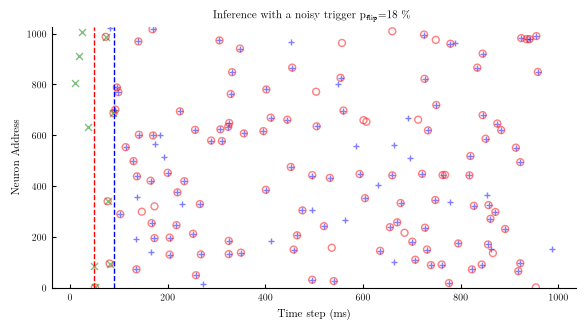

In [5]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
ax.set_title(rf"Inference with a noisy trigger $p_{{\text{{flip}}}}$={hd.pattern_object.opt.p_flip*100:.0f} % ")
printfig(fig, 'p_flip_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: fixed weights, increasing trigger noise

`get_scores_noise`: for `N_scan` values of `p_flip` (linspace 0..1) and `N_cv`
independent realisations each, trigger the network and score the evoked window; the
trigger itself is corrupted (`target_ = pattern_object()`) while scoring still uses the
clean stored target - i.e. classic **pattern completion from a degraded cue**.
Results cached as `<datetag>_noise.npz` (arrays `p_flip`, `scores_np`) under the standard
`.lock` protocol.

In [6]:
# Fixed-weights sweep with N_cv repetitions per scan point: each repetition is an
# independent stochastic cue (flip seed passed to pattern_object, spontaneous pads
# seeded by torch.manual_seed - nb 20''s seed += 1 convention), scored against the
# clean frozen_target: classic pattern completion from a degraded cue. The cache is
# written after every scan point (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0, 1, N_scan, endpoint=True)
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_scan in trange(N_scan):
        for i_cv in range(N_cv):
            with torch.no_grad():
                hd.pattern_object.opt.p_flip = p_flip[i_scan]
                torch.manual_seed(seed)
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip = data['p_flip']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
        ##################
        p_flip, scores_np = get_scores_noise()
        ##################
        np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_noise.npz


In [7]:
# Reload the fixed-weights sweep (with named keys, tolerant of the n_done field).

data = np.load(npy_filename)
p_flip, scores_np = data['p_flip'], data['scores_np']

In [8]:
# Layout constants for the scan figures (spine styling).

subplotpars_scan = SubplotParams(left=0.125, right=.95, bottom=0.25, top=.975)


File ../figures/p_flip_score.pdf already exists. Skipping save.
File ../figures/p_flip_score.png already exists. Skipping save.
File ../figures/p_flip_score.svg already exists. Skipping save.


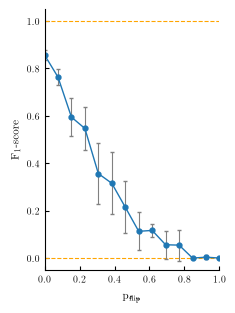

In [9]:
# $F_1$ as a function of the bit-flipping probability $p_\mathrm{flip}$: mean +/- std over N_cv realisations.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], p_flip[0], p_flip[-1], 'orange', ls='--', lw=0.8)
    ax.errorbar(p_flip, scores_np.mean(axis=1), yerr=scores_np.std(axis=1), fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"$p_\mathrm{flip}$")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(p_flip[0], p_flip[-1])
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'p_flip_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)


# Control: re-train the network for each noise level to improve WM

If graceful degradation is caused by training at `p_flip=0.01` only, training a *matched*
model per noise level should push the whole F1 curve up. Hypothesis under test:
robustness to corrupted cues is learnable (data augmentation at the right level).
Each scan point trains a fresh readout (`learn_model`, `verbose=False`) on a `Params`
instantiated with that `p_flip`, then evaluates it N_cv times with the same protocol as
the fixed-weights sweep. Cached as `<datetag>_noise_retrain.npz`.

In [10]:
# Control condition: one freshly trained model per p_flip (learning hoisted out of the
# CV loop, with local variables so the global hd/opt/model_filename are left untouched),
# then evaluated N_cv times under the same seeded protocol and the same frozen-target
# reference as the fixed-weights sweep. Incremental save with an n_done sentinel.

def get_scores_retrain_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0., 1., N_scan, endpoint=True)
    scores_np = np.zeros((N_scan, N_cv))
    i_start = 0
    seed = opt.seed + opt.N_cv * i_start # base seed, incremented per repetition (nb 20 convention)
    if npy_filename.exists(): # resume: each scan point re-seeds itself (Params.__post_init__),
        data = np.load(npy_filename) # so cached rows are valid; continue after n_done
        if data['scores_retrain_np'].shape == (N_scan, N_cv):
            scores_np = data['scores_retrain_np']
            i_start = int(data['n_done']) if 'n_done' in data else N_scan
    for i_scan in trange(i_start, N_scan):
        ##################
        opt_local = Params(p_flip=p_flip[i_scan])
        model_filename_local = data_cache / f"{opt_local.datetag}_vanilla.pth"
        hd_local = load(opt_local, model_filename_local)
        # REDUNDANT: hd_local.pattern_object.opt.p_flip = p_flip[i_scan]
        hd_local.learn_model(verbose=False)
        ##################
        target_evoked = hd_local.pattern_object.frozen_target[:, :, hd_local.opt.num_delay:]
        for i_cv in range(N_cv):
            with torch.no_grad():
                torch.manual_seed(seed)
                target_ = hd_local.pattern_object(seed=seed)
                input_spikes = hd_local.get_input_spikes(target=target_)
                _, _, spikes = hd_local.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd_local.opt.N_pretime+hd_local.opt.num_delay):(hd_local.opt.N_time+hd_local.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, p_flip_retrain=p_flip, scores_retrain_np=scores_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise_retrain.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip_retrain = data['p_flip_retrain']
    scores_retrain_np = data['scores_retrain_np']
    if data['scores_retrain_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (int(data['n_done']) != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, resuming.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        p_flip_retrain, scores_retrain_np = get_scores_retrain_noise()
         ##################
        np.savez(npy_filename, p_flip_retrain=p_flip_retrain, scores_retrain_np=scores_retrain_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_noise_retrain.npz


In [11]:
# Reload the retrain control (robust to the scan cell having taken the locked branch).

try:
    data = np.load(npy_filename)
    p_flip_retrain, scores_retrain_np = data['p_flip_retrain'], data['scores_retrain_np']
    print(f"Retrain scores loaded from {npy_filename}")
except FileNotFoundError:
    p_flip_retrain, scores_retrain_np = None, None
    print(f"Retrain score file not available yet: {npy_filename} (locked or not computed).")

Retrain scores loaded from ../cached_data/2026-09-07_noise_retrain.npz


File ../figures/p_flip_retrain_score.pdf already exists. Skipping save.
File ../figures/p_flip_retrain_score.png already exists. Skipping save.
File ../figures/p_flip_retrain_score.svg already exists. Skipping save.


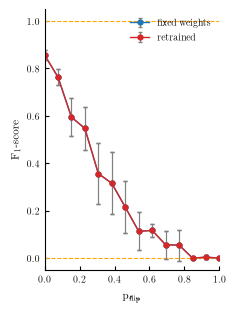

In [12]:
# Overlay fixed-weights (blue) vs re-trained (red) $F_1$ vs $p_\mathrm{flip}$.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], p_flip[0], p_flip[-1], 'orange', ls='--', lw=0.8)
    ax.errorbar(p_flip, scores_np.mean(axis=1), yerr=scores_np.std(axis=1), fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0, label='fixed weights')
    if scores_retrain_np is not None:
        ax.errorbar(p_flip_retrain, scores_retrain_np.mean(axis=1), yerr=scores_retrain_np.std(axis=1), fmt='o',
                    color='tab:red', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                    markersize=3.5, linestyle='solid', linewidth=1.0, label='retrained')
    ax.set_xlabel(r"$p_\mathrm{flip}$")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(p_flip[0], p_flip[-1])
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='best')

    printfig(fig, 'p_flip_retrain_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
